# Task 20: Manual Stacked Bar Chart

## Objective
To visualize the relationship between sex and target using a stacked
bar chart constructed with low-level Matplotlib patches. The chart
compares target proportions within each sex category.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

df = pd.read_csv("../../datasets/heart.csv")

print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (1025, 14)
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  


In [3]:
if "sex" not in df.columns or "target" not in df.columns:
    raise ValueError("Dataset must contain 'sex' and 'target' columns.")

data = df[["sex", "target"]].dropna()

sex_values = sorted(data["sex"].unique())
target_values = sorted(data["target"].unique())

counts = {}

for sex_value in sex_values:
    counts[sex_value] = {}

    for target_value in target_values:
        count = 0

        for i in range(len(data)):
            if (
                data["sex"].iloc[i] == sex_value
                and data["target"].iloc[i] == target_value
            ):
                count += 1

        counts[sex_value][target_value] = count

print("Observed counts:")
for sex_value in sex_values:
    print(sex_value, counts[sex_value])

Observed counts:
0 {np.int64(0): 86, np.int64(1): 226}
1 {np.int64(0): 413, np.int64(1): 300}


In [5]:
proportions = {}

for sex_value in sex_values:
    total = sum(counts[sex_value].values())
    proportions[sex_value] = {}

    for target_value in target_values:
        if total > 0:
            proportions[sex_value][target_value] = (
                counts[sex_value][target_value] / total
            )
        else:
            proportions[sex_value][target_value] = 0

print("Target proportions within each sex category:")

for sex_value in sex_values:
    print(sex_value, proportions[sex_value])

Target proportions within each sex category:
0 {np.int64(0): 0.27564102564102566, np.int64(1): 0.7243589743589743}
1 {np.int64(0): 0.5792426367461431, np.int64(1): 0.42075736325385693}


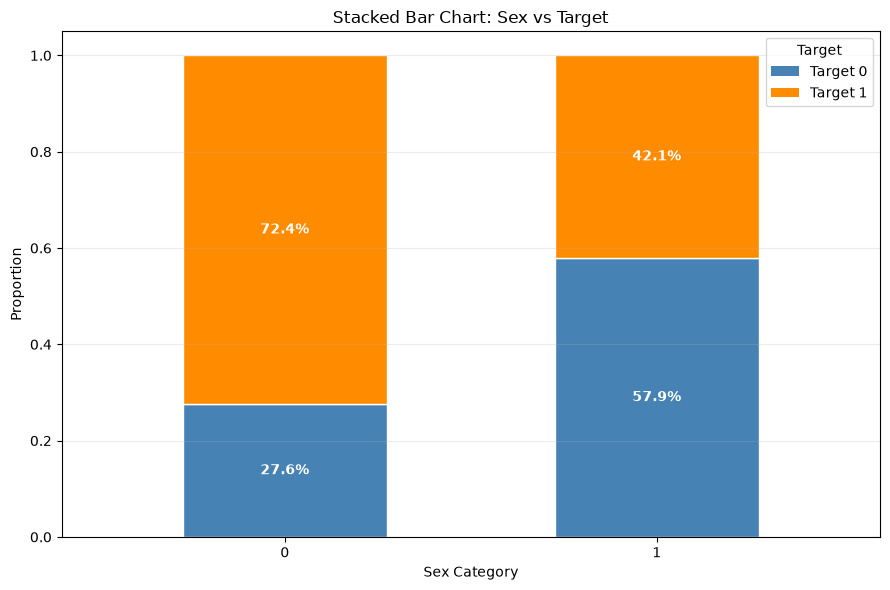

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))

colors = ["steelblue", "darkorange", "seagreen", "purple"]
bar_width = 0.55

for x_position, sex_value in enumerate(sex_values):
    bottom = 0

    for j, target_value in enumerate(target_values):
        proportion = proportions[sex_value][target_value]

        rect = Rectangle(
            (x_position - bar_width / 2, bottom),
            bar_width,
            proportion,
            facecolor=colors[j % len(colors)],
            edgecolor="white",
            linewidth=1
        )

        ax.add_patch(rect)

        if proportion > 0.04:
            ax.text(
                x_position,
                bottom + proportion / 2,
                f"{proportion:.1%}",
                ha="center",
                va="center",
                color="white",
                fontsize=10,
                fontweight="bold"
            )

        bottom += proportion

ax.set_xlim(-0.6, len(sex_values) - 0.4)
ax.set_ylim(0, 1.05)

ax.set_xticks(range(len(sex_values)))
ax.set_xticklabels([str(value) for value in sex_values])

ax.set_xlabel("Sex Category")
ax.set_ylabel("Proportion")
ax.set_title("Stacked Bar Chart: Sex vs Target")

legend_handles = []

for j, target_value in enumerate(target_values):
    legend_handles.append(
        Rectangle(
            (0, 0),
            1,
            1,
            facecolor=colors[j % len(colors)],
            label=f"Target {target_value}"
        )
    )

ax.legend(handles=legend_handles, title="Target")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

## Conclusion

A stacked bar chart was constructed using Matplotlib Rectangle patches
without using high-level bar chart functions. Counts and proportions
were calculated manually for each sex and target combination. Each bar
represents the target-class proportions within a sex category, allowing
visual comparison between groups.